# Week 1, core 2: The machine-learning workflow, with linear regression

Every method in this course, from a straight line to a transformer, is used through the same five steps: a **question**, **data**, a **model** fitted by minimizing a **loss**, an **evaluation** on data the model has not seen, and an **interpretation**. This notebook walks the whole loop once with the simplest possible model, a straight line, so that the loop itself is what you remember.

## What you will learn

- The five steps of the workflow and what each one produces.
- What a loss function measures, and how *gradient descent* lowers it one step at a time.
- Why a model is judged on data it did not see, and how a train/test split provides that data.
- The scikit-learn pattern `model.fit(X, y)` → `model.predict(X)` that Weeks 1–3 use everywhere.


In [2]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## Steps 1 and 2: a question and some data

**Question:** how does the long-term streamflow of a river catchment depend on how much rain it receives? Hydrologists expect "more rain, more flow", but how much more, and how tight is the relationship?

Real data for this question are the subject of the lab. Here we use **synthetic** data, numbers we generate ourselves from a rule we choose, because then we know the right answer and can check that the method recovers it. The rule: flow is 0.45 times precipitation (both in mm/day), plus a small constant, plus noise standing in for everything we did not measure.


In [3]:
n_catchments = 60

precip = np.random.uniform(1.0, 6.0, size=n_catchments)                 # mm/day,  shape (n_catchments,)
true_slope, true_intercept = 0.45, 0.10
noise = np.random.normal(0.0, 0.25, size=n_catchments)
flow = true_intercept + true_slope * precip + noise                      # mm/day,  shape (n_catchments,)

print(precip.shape, flow.shape)
print(f"precipitation from {precip.min():.2f} to {precip.max():.2f} mm/day")
print(f"flow from {flow.min():.2f} to {flow.max():.2f} mm/day")


(60,) (60,)
precipitation from 1.10 to 5.85 mm/day
flow from 0.40 to 2.97 mm/day


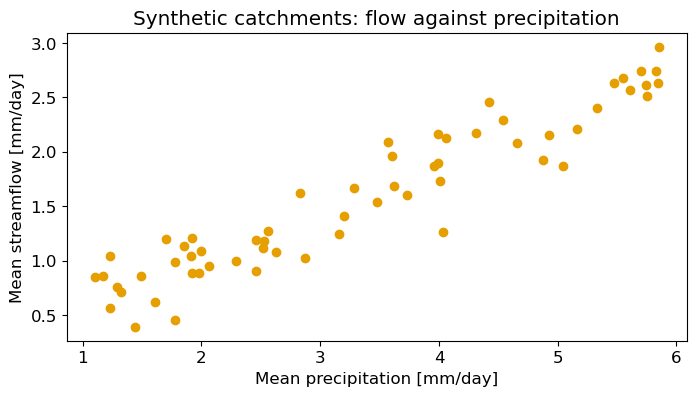

In [4]:
fig, ax = plt.subplots()
ax.scatter(precip, flow)
ax.set_xlabel("Mean precipitation [mm/day]")
ax.set_ylabel("Mean streamflow [mm/day]")
ax.set_title("Synthetic catchments: flow against precipitation")
plt.show()


Sixty points rising from lower left to upper right, scattered within about half a millimeter per day of the trend; nothing has been fitted yet.

Always look at the data before modeling it: the shape of the arrays, their ranges and units, and one plot. In the lab this step will also catch missing values and odd units; here it confirms that the rule we chose did what we meant.

## Step 3: a model and a loss

A **model** is a rule that turns inputs into a prediction. The simplest one for this picture is a straight line,

$$\hat{y} = w\,x + b,$$

where $x$ is precipitation, $\hat{y}$ (read "y-hat") is the predicted flow, and the two numbers $w$ (the slope) and $b$ (the intercept) are the model's **parameters**: the knobs we are allowed to turn. In the code, $w$ is `w`, $b$ is `b`, and $\hat{y}$ is `flow_pred`.

How do we know whether a particular `w` and `b` are good? We need a single number that says how wrong the predictions are. That number is the **loss**. The one used for regression almost everywhere is the **mean squared error** (MSE), the average of the squared differences between prediction and truth:

$$\text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n}\big(w\,x_i + b - y_i\big)^2.$$

Squaring makes every error positive and punishes large errors much more than small ones. Smaller MSE is better; zero would be perfect.


In [5]:
def mse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean((y - y_pred) ** 2))

# Three guesses for (w, b). Which one is best?
for w, b in [(0.2, 1.0), (0.6, -0.3), (0.45, 0.1)]:
    flow_pred = w * precip + b
    print(f"w = {w:.2f}, b = {b:+.2f}   ->   MSE = {mse(flow, flow_pred):.4f}  (mm/day)^2")


w = 0.20, b = +1.00   ->   MSE = 0.1788  (mm/day)^2
w = 0.60, b = -0.30   ->   MSE = 0.1285  (mm/day)^2
w = 0.45, b = +0.10   ->   MSE = 0.0497  (mm/day)^2


The third guess is the rule we generated the data from, and its MSE is the smallest: about the variance of the noise we added, $0.25^2 \approx 0.06$. No line can do better than the noise allows.

Because there are only two parameters, we can draw the whole loss as a landscape: MSE as a function of $w$ and $b$.


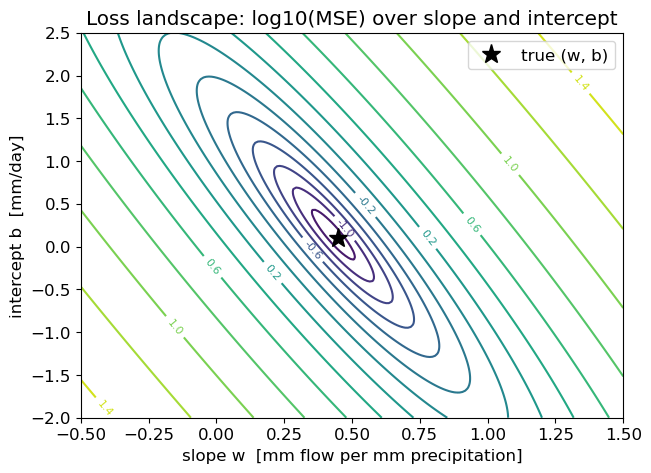

In [6]:
w_grid = np.linspace(-0.5, 1.5, 200)
b_grid = np.linspace(-2.0, 2.5, 200)
W, B = np.meshgrid(w_grid, b_grid)                                        # (200, 200) each

loss_surface = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        loss_surface[i, j] = mse(flow, W[i, j] * precip + B[i, j])

fig, ax = plt.subplots(figsize=(7, 5))
contours = ax.contour(W, B, np.log10(loss_surface), levels=15, cmap="viridis")
ax.clabel(contours, levels=contours.levels[::2], fmt="%.1f", fontsize=8)   # label every other level
ax.plot(true_slope, true_intercept, "k*", markersize=14, label="true (w, b)")
ax.set_xlabel("slope w  [mm flow per mm precipitation]")
ax.set_ylabel("intercept b  [mm/day]")
ax.set_title("Loss landscape: log10(MSE) over slope and intercept")
ax.legend()
plt.show()


A bowl with a single lowest point near the true parameters (the star). Contour labels are the base-10 logarithm of the MSE, so each unit is a factor of ten. The bowl is a long, tilted valley rather than a round dish: many combinations of slope and intercept give nearly the same loss, which is why fitting will be slow in one direction and fast in the other.

> **Check your understanding.** The MSE has units of (mm/day)². Which quantity, with the same units as the data, would you report to a colleague instead, and how is it computed from the MSE?

## Step 3, continued: fitting by gradient descent

We could read the best $(w, b)$ off the plot, but with 27 parameters (the lab) or a million (Week 6) there is no plot to read. Instead we **walk downhill**. The gradient of the loss, its slope with respect to each parameter, points uphill; so we take a small step the other way, over and over. For the MSE and the straight line the two slopes are

$$\frac{\partial\,\text{MSE}}{\partial w} = \frac{2}{n}\sum_i x_i\,(w x_i + b - y_i), \qquad
\frac{\partial\,\text{MSE}}{\partial b} = \frac{2}{n}\sum_i (w x_i + b - y_i).$$

Each step moves the parameters by the gradient times a small number, the **learning rate**. One pass through the data is called an **epoch**. Later in the course a library will compute the gradients for you; the loop below is what it does under the hood, and its five numbered lines are the training loop you will see all semester.


In [7]:
learning_rate = 0.05
n_epochs = 300

w, b = 0.0, 0.0                          # 1. start somewhere (here: a flat line through zero)

losses = []
for epoch in range(n_epochs):
    flow_pred = w * precip + b                                   # 2. forward pass: predictions with the current parameters
    loss = mse(flow, flow_pred)                                  # 3. how wrong are we?
    grad_w = 2 * np.mean(precip * (flow_pred - flow))            # 4. gradients: which way is uphill for w ...
    grad_b = 2 * np.mean(flow_pred - flow)                       #    ... and for b
    w = w - learning_rate * grad_w                               # 5. step downhill
    b = b - learning_rate * grad_b
    losses.append(loss)
    if epoch % 50 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:3d}   loss {loss:.4f}   w = {w:.3f}   b = {b:+.3f}")

print(f"\ntrue values:  w = {true_slope:.3f}   b = {true_intercept:+.3f}")


epoch   0   loss 2.9734   w = 0.626   b = +0.158
epoch  50   loss 0.0484   w = 0.435   b = +0.127
epoch 100   loss 0.0484   w = 0.433   b = +0.135
epoch 150   loss 0.0484   w = 0.432   b = +0.138
epoch 200   loss 0.0484   w = 0.432   b = +0.140
epoch 250   loss 0.0484   w = 0.432   b = +0.140
epoch 299   loss 0.0484   w = 0.431   b = +0.141

true values:  w = 0.450   b = +0.100


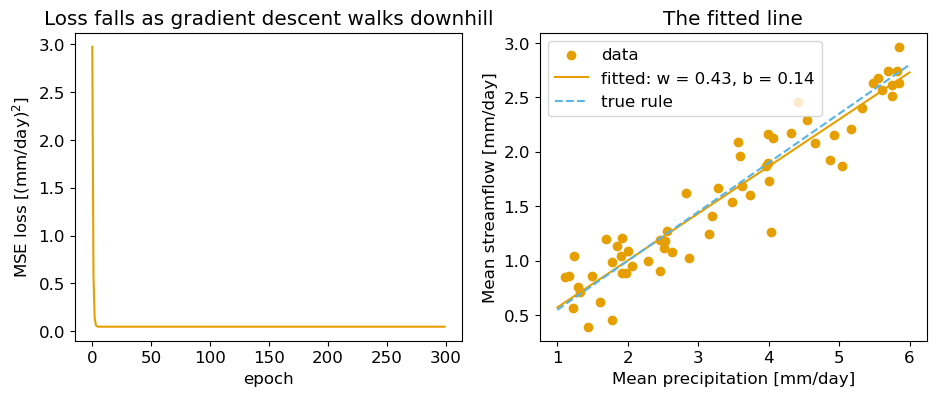

In [8]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(11, 4))

ax_left.plot(losses)
ax_left.set_xlabel("epoch")
ax_left.set_ylabel("MSE loss [(mm/day)$^2$]")
ax_left.set_title("Loss falls as gradient descent walks downhill")

ax_right.scatter(precip, flow, label="data")
x_line = np.linspace(1.0, 6.0, 50)
ax_right.plot(x_line, w * x_line + b, label=f"fitted: w = {w:.2f}, b = {b:.2f}")
ax_right.plot(x_line, true_slope * x_line + true_intercept, "--", label="true rule")
ax_right.set_xlabel("Mean precipitation [mm/day]")
ax_right.set_ylabel("Mean streamflow [mm/day]")
ax_right.set_title("The fitted line")
ax_right.legend()
plt.show()


Left: the loss drops steeply in the first few epochs and then flattens near the noise floor. Right: the fitted line (solid) lies almost on top of the rule that generated the data (dashed); the small remaining gap is the noise.

The **loss curve** on the left is the most important diagnostic in this course. You will plot one every time something is trained.

> **Exercise.** Predict what happens to the loss curve if the learning rate is made ten times larger, `learning_rate = 0.5`: does the loss fall faster, fall then flatten at the same level, oscillate, or grow? Write your prediction down, then copy the two cells above into the cell below, change the one number, and run. Then try ten times *smaller*, `0.005`, and compare. When you are done, re-run the original gradient-descent cell above, so that the rest of the notebook sees the converged `w` and `b` rather than your experiment's.


In [9]:
# Exercise: work here (copy the gradient-descent cell and the plotting cell, change only learning_rate).
np.random.seed(seed)


## Step 3, the scikit-learn way

Writing the gradients by hand was for understanding. In practice, Weeks 1–3 use **scikit-learn**, a library in which every model follows the same two-call pattern:

```python
model = LinearRegression()        # choose the model
model.fit(X, y)                   # fit it: find the parameters that minimize the loss
y_pred = model.predict(X_new)     # use it
```

One rule to remember: scikit-learn wants the inputs `X` as a **two-dimensional** array of shape `(n_samples, n_features)`, even when there is a single feature. Two words you will use all semester: each row of `X` is a **sample** (here, one catchment) and each column is a **feature** (one measured property of it). Our `precip` array is one-dimensional, shape `(60,)`, so we reshape it to `(60, 1)`: sixty samples, one feature. The target `y` stays one-dimensional.


In [10]:
X = precip.reshape(-1, 1)          # (n_catchments, 1): one column = one feature
y = flow                           # (n_catchments,)
print(X.shape, y.shape)

model = LinearRegression()
model.fit(X, y)

print(f"scikit-learn:      w = {model.coef_[0]:.3f}   b = {model.intercept_:+.3f}")
print(f"gradient descent:  w = {w:.3f}   b = {b:+.3f}")
print(f"true rule:         w = {true_slope:.3f}   b = {true_intercept:+.3f}")


(60, 1) (60,)
scikit-learn:      w = 0.431   b = +0.141
gradient descent:  w = 0.431   b = +0.141
true rule:         w = 0.450   b = +0.100


Scikit-learn solves the least-squares problem exactly (there is a closed formula for a straight line), and lands on the same numbers that gradient descent walked to. For a straight line the walk was unnecessary; for the models of Week 4 onward there is no formula, and the walk is all we have.

> **Check your understanding.** Of the five steps of the workflow, which one does `model.fit` carry out, and which one does `model.predict` serve?

## Step 4: evaluate on data the model has not seen

So far we judged the model on the same points it was fitted to. That flatters any model, and it flatters flexible models outrageously (watch below). The honest measure is performance on **test data**: points the model never saw during fitting (you will also hear "held-out data"). The simplest way to get such data is a random **train/test split**.

The `random_state=seed` argument makes the split the same every time this cell runs. You will see `random_state` in every tutorial; in this course the setup cell's seed already fixes the randomness of a top-to-bottom run, so we pass it only where a single cell must be repeatable on its own.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)
print(X_train.shape, X_test.shape)          # 45 catchments to fit on, 15 to test on

def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

model = LinearRegression()
model.fit(X_train, y_train)

print(f"train RMSE: {rmse(y_train, model.predict(X_train)):.3f} mm/day")
print(f"test  RMSE: {rmse(y_test,  model.predict(X_test)):.3f} mm/day")


(45, 1) (15, 1)
train RMSE: 0.227 mm/day
test  RMSE: 0.202 mm/day


The root-mean-square error (RMSE) is the square root of the MSE, back in the units of the data: on average the line is off by about a quarter of a millimeter per day, on the training points and on the unseen ones alike. A model whose test error is close to its training error has **generalized**.

Now the deliberate failure. Take only 20 of the 45 training points and fit two models to them: the straight line again, and a polynomial of degree 12, which has 13 parameters and can bend to pass close to every one of the 20 points. Both are judged on the same 15 test points.


straight line           train RMSE 0.229   test RMSE 0.186 mm/day
degree-12 polynomial    train RMSE 0.130   test RMSE 0.311 mm/day


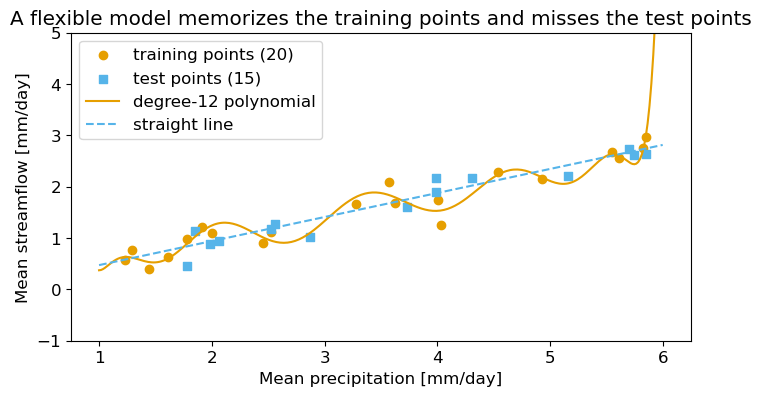

In [12]:
degree = 12
n_small = 20                             # fewer training points make the failure easier to see
x_small = X_train[:n_small, 0]           # back to 1-D for the polynomial fit
y_small = y_train[:n_small]
x_test = X_test[:, 0]

line_fit = np.polynomial.Polynomial.fit(x_small, y_small, deg=1)        # the straight line, fitted to the same 20 points
poly = np.polynomial.Polynomial.fit(x_small, y_small, deg=degree)
for name, fit in [("straight line", line_fit), (f"degree-{degree} polynomial", poly)]:
    print(f"{name:22s}  train RMSE {rmse(y_small, fit(x_small)):.3f}   test RMSE {rmse(y_test, fit(x_test)):.3f} mm/day")

fig, ax = plt.subplots()
ax.scatter(x_small, y_small, label="training points (20)")
ax.scatter(x_test, y_test, marker="s", label="test points (15)")
x_line = np.linspace(1.0, 6.0, 300)
ax.plot(x_line, poly(x_line), label=f"degree-{degree} polynomial")
ax.plot(x_line, line_fit(x_line), "--", label="straight line")
ax.set_ylim(-1, 5)
ax.set_xlabel("Mean precipitation [mm/day]")
ax.set_ylabel("Mean streamflow [mm/day]")
ax.set_title("A flexible model memorizes the training points and misses the test points")
ax.legend()
plt.show()


The polynomial threads the training points: its training RMSE is well below the line's, but its test RMSE is far worse, and beyond the last training point it shoots off the top of the plot, to values no catchment could have. This is **overfitting**: the model learned the noise of the training set instead of the rule. Week 2 is about this trade-off and how regularization tames it; for now the lesson is simpler. **The number that matters is the test error.**

One confession: we have just used the test set to decide which of two models is better, which is exactly what a test set should *not* be used for (we are peeking to make a point). Choosing between models is the job of Week 2's validation set.

> **Check your understanding.** Why can the straight line's test RMSE not fall much below the 0.25 mm/day of noise we added, and what would have to change in the data for a lower test RMSE to be possible?

> **Exercise.** Predict first: with `degree = 3` instead of 12, will the polynomial's test RMSE be closer to the straight line's or to the degree-12 polynomial's? Change the one number in the cell above, re-run it, and look. Put it back to 12 afterwards and re-run.

> **Warning.** A train/test split only tells the truth if the test points are genuinely independent of the training points. River catchments next to each other, or measurements from consecutive days, are not independent; Week 3 is about how that leaks information and how to split properly.

## Step 5: interpret

A fitted model is an answer to the question we started with, so the last step is to say what it means in the language of the problem. Here: the fitted slope is about 0.43 (the rule we generated the data from used 0.45), so in these synthetic catchments each extra millimeter per day of precipitation produces a little under half a millimeter per day of extra streamflow; the rest returns to the atmosphere as evapotranspiration. The intercept is near zero, so a catchment with no rain has no flow.

The RMSE says a single catchment's flow is predicted to within about a quarter of a millimeter per day. In the lab you will write a paragraph like this about real catchments, and it will be the part of the work that no assistant can do for you.


## Summary

- The workflow is question → data → model → evaluation → interpretation, and the same five steps carry every method in this course.
- A loss function (MSE for regression) measures how wrong a model is; gradient descent lowers it by stepping against the gradient, with the learning rate setting the step size.
- Models are judged on test data they did not see; the training error flatters flexible models.
- Scikit-learn's `fit` / `predict` pattern, with `X` of shape `(n_samples, n_features)`, is how Weeks 1–3 use every model.


## Exercise solutions

### Exercise 1 (learning rate × 10 and ÷ 10)

With `learning_rate = 0.5` the steps overshoot the bottom of the valley: the loss grows from epoch to epoch and the printed numbers become enormous (or `inf`/`nan`). With `0.005` the loss still falls but much more slowly, and after 300 epochs the intercept (`b` = 0.12) has not reached the least-squares value of 0.14 that the `0.05` run found. The loss curve barely shows this, because the unfinished direction is the flat one in the loss landscape; look at the printed `w` and `b`, not only at the curve. A learning rate is a trade-off between speed and stability, and finding one that works is part of every training run in this course.

### Exercise 2 (degree 3)

A cubic has only 4 parameters and cannot thread 20 points, so it behaves almost like the line: train RMSE 0.221 and test RMSE 0.211, against the line's 0.229 and 0.186 and the degree-12 polynomial's 0.130 and 0.311. Flexibility is a dial, not a switch; Week 2 turns it slowly.

### Check-your-understanding answers

- *Units.* Report the root-mean-square error, RMSE = sqrt(MSE), which is back in mm/day.
- *fit and predict.* `model.fit` is step 3, fitting the model (finding the parameters that minimize the loss); `model.predict` produces the predictions that step 4, evaluation, scores against the test data, and that any later use of the model needs.
- *The noise floor.* The straight line is the rule the data came from, so what remains is the 0.25 mm/day of noise we added, which no model can predict. Only less noisy data (a smaller noise standard deviation, or more measured features that explain some of the spread) would allow a lower test RMSE.
